In [1]:
import pandas as pd

df = pd.read_csv("data/audi.csv")
df.head()

,model,year,price,transmission,mileage,fuelType,tax,mpg,engineSize
0,A1,2017,12500,Manual,15735,Petrol,150,55.4,1.4
1,A6,2016,16500,Automatic,36203,Diesel,20,64.2,2.0
2,A1,2016,11000,Manual,29946,Petrol,30,55.4,1.4
3,A4,2017,16800,Automatic,25952,Diesel,145,67.3,2.0
4,A3,2019,17300,Manual,1998,Petrol,145,49.6,1.0


In [2]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10668 entries, 0 to 10667
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   model         10668 non-null  object 
 1   year          10668 non-null  int64  
 2   price         10668 non-null  int64  
 3   transmission  10668 non-null  object 
 4   mileage       10668 non-null  int64  
 5   fuelType      10668 non-null  object 
 6   tax           10668 non-null  int64  
 7   mpg           10668 non-null  float64
 8   engineSize    10668 non-null  float64
dtypes: float64(2), int64(4), object(3)
memory usage: 750.2+ KB


In [3]:
filer = {
    "audi.csv": "Audi", "bmw.csv": "BMW", "ford.csv": "Ford",
    "hyundi.csv": "Hyundai", "merc.csv": "Mercedes", "skoda.csv": "Skoda",
    "toyota.csv": "Toyota", "vauxhall.csv": "Vauxhall", "vw.csv": "Volkswagen",
}

tabeller = []
for filnavn, merke in filer.items():
    tabell = pd.read_csv("data/" + filnavn)    
    tabell = tabell.rename(columns={"tax(£)": "tax"})
    tabell["brand"] = merke
    tabeller.append(tabell)

df = pd.concat(tabeller, ignore_index=True)
df.shape

(99187, 10)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99187 entries, 0 to 99186
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   model         99187 non-null  object 
 1   year          99187 non-null  int64  
 2   price         99187 non-null  int64  
 3   transmission  99187 non-null  object 
 4   mileage       99187 non-null  int64  
 5   fuelType      99187 non-null  object 
 6   tax           99187 non-null  int64  
 7   mpg           99187 non-null  float64
 8   engineSize    99187 non-null  float64
 9   brand         99187 non-null  object 
dtypes: float64(2), int64(4), object(4)
memory usage: 7.6+ MB


In [5]:
df.describe()

,year,price,mileage,tax,mpg,engineSize
count,99187.000000,99187.000000,99187.000000,99187.000000,99187.000000,99187.000000
mean,2017.087723,16805.347656,23058.914213,120.299838,55.166825,1.663280
std,2.123934,9866.773417,21148.523721,63.150926,16.138522,0.557646
min,1970.000000,450.000000,1.000000,0.000000,0.300000,0.000000
25%,2016.000000,9999.000000,7425.000000,125.000000,47.100000,1.200000
50%,2017.000000,14495.000000,17460.000000,145.000000,54.300000,1.600000
75%,2019.000000,20870.000000,32339.000000,145.000000,62.800000,2.000000
max,2060.000000,159999.000000,323000.000000,580.000000,470.800000,6.600000


In [6]:
df[df["year"] > 2020]

,model,year,price,transmission,mileage,fuelType,tax,mpg,engineSize,brand
39175,Fiesta,2060,6495,Automatic,54807,Petrol,205,42.8,1.4,Ford


In [7]:
df[df["year"] < 2000].sort_values("year")

,model,year,price,transmission,mileage,fuelType,tax,mpg,engineSize,brand
81235,Zafira,1970,10495,Manual,37357,Petrol,200,42.2,1.4,Vauxhall
56346,M Class,1970,24999,Automatic,14000,Diesel,305,39.2,0.0,Mercedes
20293,5 Series,1996,5995,Automatic,36000,Petrol,270,26.4,2.8,BMW
38327,Escort,1996,3000,Manual,50000,Petrol,265,34.4,1.8,Ford
20509,Z3,1997,3950,Manual,49000,Petrol,270,35.3,1.9,BMW
10427,A8,1997,4650,Automatic,122000,Petrol,265,18.9,4.2,Audi
56186,SL CLASS,1997,9995,Automatic,76000,Petrol,255,28.2,3.2,Mercedes
76255,Astra,1997,950,Manual,89233,Petrol,265,35.8,1.6,Vauxhall
56068,S Class,1998,19990,Automatic,43534,Petrol,265,23.3,6.0,Mercedes
70354,Land Cruiser,1998,19990,Manual,100000,Diesel,265,23.9,4.2,Toyota


In [8]:
df[df["engineSize"] == 0]["fuelType"].value_counts()

fuelType
Petrol      163
Diesel       69
Hybrid       38
Electric      2
Other         1
Name: count, dtype: int64

In [9]:
print("Før:", df.shape)

df = df[df["year"] <= 2020]

print("Etter:", df.shape)

Før: (99187, 10)
Etter: (99186, 10)


In [10]:
print("Før:", df.shape)

df = df[df["year"] >= 2000]

print("Etter:", df.shape)

Før: (99186, 10)
Etter: (99164, 10)


In [11]:
print("Før:", df.shape)

df = df[(df["engineSize"] > 0) | (df["fuelType"] == "Electric")]

print("Etter:", df.shape)

Før: (99164, 10)
Etter: (98894, 10)


In [12]:
df["model"].unique()[:10]

array([' A1', ' A6', ' A4', ' A3', ' Q3', ' Q5', ' A5', ' S4', ' Q2',
       ' A7'], dtype=object)

In [13]:
df["model"] = df["model"].str.strip()
df["model"].unique()[:10]

array(['A1', 'A6', 'A4', 'A3', 'Q3', 'Q5', 'A5', 'S4', 'Q2', 'A7'],
      dtype=object)

In [14]:
df.duplicated().sum()

np.int64(1470)

In [15]:
print("Før:", df.shape)
df = df.drop_duplicates()
print("Etter:", df.shape)

Før: (98894, 10)
Etter: (97424, 10)


In [16]:
df.describe()

,year,price,mileage,tax,mpg,engineSize
count,97424.000000,97424.00000,97424.000000,97424.000000,97424.000000,97424.000000
mean,2017.071153,16776.10169,23214.991912,120.138364,55.069794,1.669279
std,2.089900,9869.28008,21058.085231,63.304430,14.242247,0.552177
min,2000.000000,450.00000,1.000000,0.000000,0.300000,0.000000
25%,2016.000000,9999.00000,7670.750000,125.000000,47.100000,1.200000
50%,2017.000000,14480.00000,17672.500000,145.000000,54.300000,1.600000
75%,2019.000000,20750.00000,32497.000000,145.000000,62.800000,2.000000
max,2020.000000,159999.00000,323000.000000,580.000000,470.800000,6.600000


In [17]:
%pip install matplotlib

You should consider upgrading via the '/Users/jonas/Documents/DAT158/.venv/bin/python3 -m pip install --upgrade pip' command.
Note: you may need to restart the kernel to use updated packages.


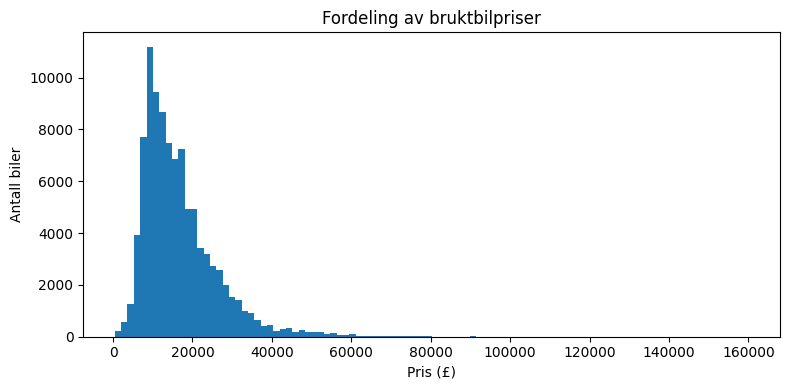

In [18]:
import matplotlib.pyplot as plt
import os

os.makedirs("figurer", exist_ok=True)

plt.figure(figsize=(8, 4))
plt.hist(df["price"], bins=100)
plt.xlabel("Pris (£)")
plt.ylabel("Antall biler")
plt.title("Fordeling av bruktbilpriser")
plt.tight_layout()
plt.savefig("figurer/pris_fordeling.png", dpi=200)
plt.show()

<Figure size 800x400 with 0 Axes>

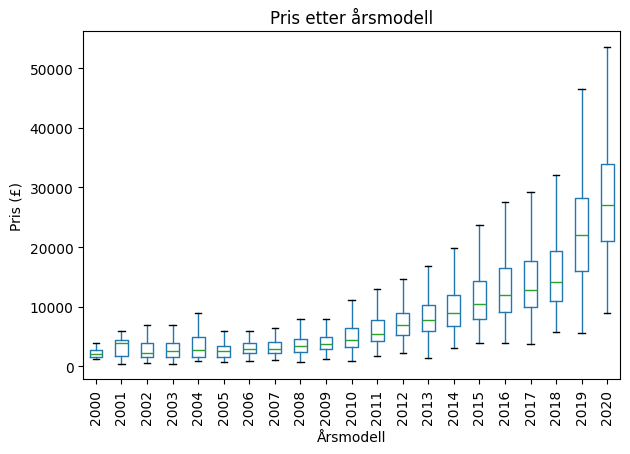

In [19]:
plt.figure(figsize=(8, 4))
df.boxplot(column="price", by="year", grid=False, showfliers=False)
plt.xlabel("Årsmodell")
plt.ylabel("Pris (£)")
plt.title("Pris etter årsmodell")
plt.suptitle("")
plt.xticks(rotation=90)
plt.tight_layout()
plt.savefig("figurer/pris_aarsmodell.png", dpi=200)
plt.show()

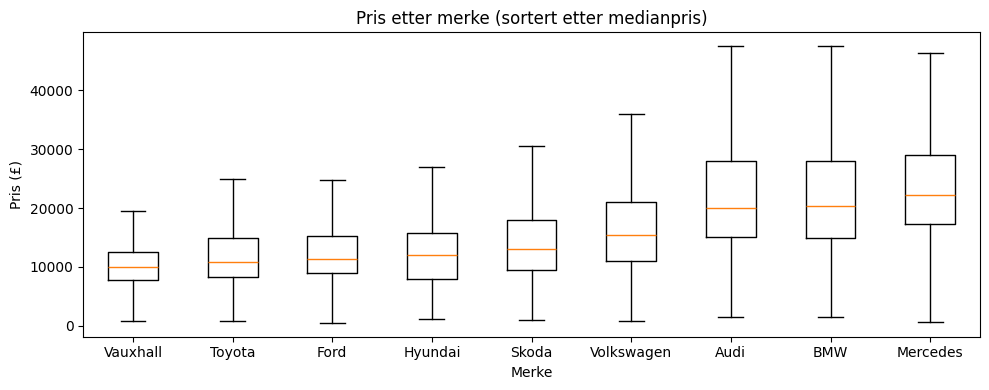

In [20]:
rekkefolge = df.groupby("brand")["price"].median().sort_values().index
data = [df.loc[df["brand"] == merke, "price"] for merke in rekkefolge]

plt.figure(figsize=(10, 4))
plt.boxplot(data, showfliers=False)
plt.xticks(range(1, len(rekkefolge) + 1), rekkefolge)
plt.xlabel("Merke")
plt.ylabel("Pris (£)")
plt.title("Pris etter merke (sortert etter medianpris)")
plt.tight_layout()
plt.savefig("figurer/pris_merke.png", dpi=200)
plt.show()

In [21]:
egenskaper = ["brand", "model", "year", "mileage", "transmission", "fuelType", "engineSize"]

X = df[egenskaper]
y = df["price"]

print(X.shape, y.shape)

(97424, 7) (97424,)


In [22]:
pd.get_dummies(df["fuelType"].head(6))

,Diesel,Petrol
0,False,True
1,True,False
2,False,True
3,True,False
4,False,True
5,False,True


In [23]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Trening:", X_train.shape)
print("Test:   ", X_test.shape)

Trening: (77939, 7)
Test:    (19485, 7)


In [24]:
from sklearn.metrics import mean_absolute_error, r2_score

def evaluer(navn, prediksjoner):
    mae = mean_absolute_error(y_test, prediksjoner)
    r2 = r2_score(y_test, prediksjoner)
    print(f"{navn:20s} MAE: £{mae:,.0f}   R²: {r2:.3f}")

In [25]:
import numpy as np

median = y_train.median()
baseline = np.full(len(y_test), median)

evaluer("Baseline (median)", baseline)

Baseline (median)    MAE: £6,789   R²: -0.050


In [26]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge

kategoriske = ["brand", "model", "transmission", "fuelType"]
numeriske = ["year", "mileage", "engineSize"]

forbehandling = ColumnTransformer([
    ("kategoriske", OneHotEncoder(handle_unknown="ignore"), kategoriske),
    ("numeriske", StandardScaler(), numeriske),
])

ridge = Pipeline([
    ("forbehandling", forbehandling),
    ("modell", Ridge()),
])

ridge.fit(X_train, y_train)
evaluer("Ridge", ridge.predict(X_test))

Ridge                MAE: £2,288   R²: 0.862


In [27]:
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor

forbehandling_tre = ColumnTransformer([
    ("kategoriske", OneHotEncoder(handle_unknown="ignore", sparse_output=False), kategoriske),
], remainder="passthrough")

random_forest = Pipeline([
    ("forbehandling", forbehandling_tre),
    ("modell", RandomForestRegressor(n_estimators=100, n_jobs=-1, random_state=42)),
])
random_forest.fit(X_train, y_train)
evaluer("Random forest", random_forest.predict(X_test))

gradient_boosting = Pipeline([
    ("forbehandling", forbehandling_tre),
    ("modell", HistGradientBoostingRegressor(max_iter=300, random_state=42)),
])
gradient_boosting.fit(X_train, y_train)
evaluer("Gradient boosting", gradient_boosting.predict(X_test))

Random forest        MAE: £1,402   R²: 0.947
Gradient boosting    MAE: £1,349   R²: 0.949


In [28]:
from sklearn.model_selection import cross_val_score

modeller = [
    ("Ridge", ridge),
    ("Random forest", random_forest),
    ("Gradient boosting", gradient_boosting),
]

for navn, modell in modeller:
    scores = cross_val_score(modell, X_train, y_train, cv=5,
                             scoring="neg_mean_absolute_error")
    mae = -scores
    print(f"{navn:20s} MAE: £{mae.mean():,.0f} ± £{mae.std():,.0f}")

Ridge                MAE: £2,304 ± £25
Random forest        MAE: £1,433 ± £11
Gradient boosting    MAE: £1,385 ± £25


In [29]:
from sklearn.model_selection import GridSearchCV

parametre = {
    "modell__learning_rate": [0.05, 0.1],
    "modell__max_iter": [300, 600],
    "modell__max_leaf_nodes": [31, 63],
}

sok = GridSearchCV(gradient_boosting, parametre, cv=3,
                   scoring="neg_mean_absolute_error", verbose=1)
sok.fit(X_train, y_train)

print("Beste parametre:", sok.best_params_)
print(f"Beste MAE (kryssvalidering): £{-sok.best_score_:,.0f}")

evaluer("Gradient boosting (tunet)", sok.best_estimator_.predict(X_test))

Fitting 3 folds for each of 8 candidates, totalling 24 fits
Beste parametre: {'modell__learning_rate': 0.05, 'modell__max_iter': 600, 'modell__max_leaf_nodes': 63}
Beste MAE (kryssvalidering): £1,359
Gradient boosting (tunet) MAE: £1,306   R²: 0.952


In [30]:
beste = sok.best_estimator_ 

resultater = X_test.copy()
resultater["pris"] = y_test
resultater["estimat"] = beste.predict(X_test)
resultater["feil"] = (resultater["estimat"] - resultater["pris"]).abs()
resultater["feil_prosent"] = resultater["feil"] / resultater["pris"] * 100

resultater.groupby("brand")[["feil", "feil_prosent"]].mean().sort_values("feil")

,feil,feil_prosent
brand,,
Vauxhall,750.575886,7.815279
Toyota,874.677018,7.428149
Ford,888.401930,7.529846
Hyundai,926.560133,7.584647
Skoda,1124.729868,8.223976
Volkswagen,1280.054199,7.891157
Audi,1789.441578,8.184014
BMW,1921.661778,8.972878
Mercedes,2056.033595,8.605810


In [31]:
resultater["prisklasse"] = pd.cut(resultater["pris"],
                                  bins=[0, 10000, 20000, 30000, 50000, 200000])
resultater.groupby("prisklasse", observed=True)[["feil", "feil_prosent"]].mean()

,feil,feil_prosent
prisklasse,,
"(0, 10000]",653.030155,9.401090
"(10000, 20000]",1070.202267,7.335215
"(20000, 30000]",1867.598570,7.610802
"(30000, 50000]",3241.041101,8.716307
"(50000, 200000]",5879.698481,8.856393


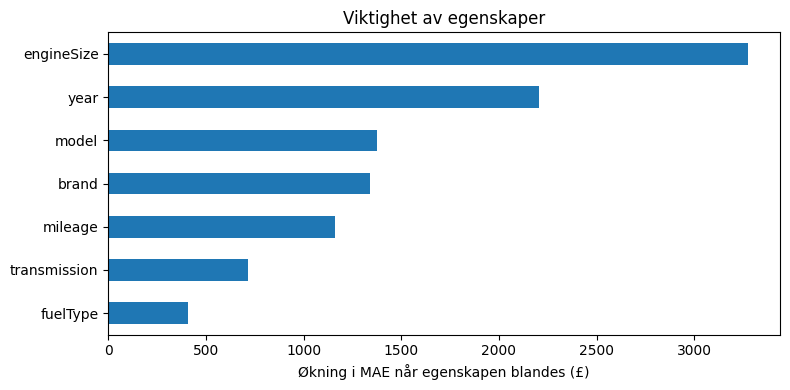

In [32]:
from sklearn.inspection import permutation_importance

viktighet = permutation_importance(
    beste, X_test, y_test, n_repeats=5, random_state=42,
    scoring="neg_mean_absolute_error",
)

viktighet = pd.Series(viktighet.importances_mean, index=X_test.columns).sort_values()

plt.figure(figsize=(8, 4))
viktighet.plot.barh()
plt.xlabel("Økning i MAE når egenskapen blandes (£)")
plt.title("Viktighet av egenskaper")
plt.tight_layout()
plt.savefig("figurer/feature_importance.png", dpi=200)
plt.show()

In [33]:
import joblib
import json

beste = sok.best_estimator_
joblib.dump(beste, "model.joblib")

meta = {
    "mae": round(mean_absolute_error(y_test, beste.predict(X_test))),
    "feil_prosent": round(resultater["feil_prosent"].mean(), 1),
    "modeller_per_merke": {
        merke: sorted(gruppe["model"].unique().tolist())
        for merke, gruppe in df.groupby("brand")
    },
    "girkasser": sorted(df["transmission"].unique().tolist()),
    "drivstoff": sorted(df["fuelType"].unique().tolist()),
    "aar": [int(df["year"].min()), int(df["year"].max())],
}

with open("meta.json", "w", encoding="utf-8") as f:
    json.dump(meta, f, ensure_ascii=False, indent=2)

print(meta["mae"], meta["feil_prosent"], meta["aar"])

1306 8.0 [2000, 2020]


In [34]:
import sklearn
sklearn.__version__

'1.6.1'